# 1. házi feladat

Az első házi feladat során egy egyszerű Multi-layer Perceptron (MLP) típusú neuronhálót kell betanítani és kiértékelni egy regressziós és egy klasszifikációs feladaton a PyTorch könyvtár segítségével.

A házi feladat több részfeladatból áll (A - I), melyek egymásra épülnek. A feladat automatikus tesztelőszkripttel rendelkezik és vizsgálja az egyes részfeladatokra adott megoldások helyességét. Éppen ezért, **ne változtasd meg a notebook struktúráját**, ne szedd több részre, illetve ne módosítsd a megírt részeket, csak a megoldásaidat írd be a megfelelő helyre, különben nem fogjuk tudni értékelni! A megoldások az `# Implement your solution BELOW` és `# Implement your solution ABOVE` sorok közé írandók. Ha a megoldott részfeladatok futtatásakor a "Tester: .... OK" felirat megjelenik, _vélhetően_ jó a megoldás. Azonban, a tesztelőszkript nem képes a megoldás helyességét minden aspektus szerint ellenőrizni. Így elképzelhető, hogy beadás után további javításokat kérünk a megoldásban. A beadott házi feladatok gépi tanulás alapú plágiumellenőrzésen esnek át. Másolás gyanújának felmerülése esetén mind a másolat(ok), mind az azt/azokat ihlető eredeti megoldások visszautasíthatók.

**!!! A feladatok megoldását, vagy az arra mutató linkeket bárhol közzétenni tilos !!!**

Elakadás esetén javasolt átnézni a Canvason megosztott segédanyag notebookokat és videókat, illetve az előadások anyagát. A Canvas fórumon "HF1 GYIK" névvel, a gyakori kérdéseket és válaszokat gyűjtjük össze. Továbbá, kérhető segítség az oktatóktól is, például a Teams rendszeren keresztül. Ehhez, kérjük a kurzus Canvas oldalán a legfelső modulban található _"
Teams beszélgetés indítása az oktatókkal"_ linket használni: ez egy Teams beszélgetést kezdeményez az összes oktatóval egyidejűleg.

**Megoldás és beküldés menete:**

A közzétett, feladatokat tartalmazó Jupyter notebook a Google Drive-on keresztül lett megosztva, így a Google saját Jupyter notebook szerkesztője és futtatókörnyezete nyílik meg a linkre kattintáskor, a Google Colab. Ennek segítségével online szerkeszthető és futtatható a megosztott notebook. Mivel a notebook csak "view" jogosultságokkal van megosztva, a Google Colab az úgynevezett "Playground" módban nyitja azt meg, ahol bár szerkeszthető és futtatható a notebook, de a változtatások nem lesznek automatikusan mentve. A notebook maradandó hatásokkal járó szerkesztése az alábbi módokon lehetséges:
- Javasolt a notebook-ot letölteni (.ipynb fájl) és a saját számítógépen telepített Python környezettel, `jupyterlab`, vagy `notebook` csomagok segítségével használni, hiszen a ZH alatt is ilyen környezettel kell majd dolgozni. További információk erről a környezetről a "Szoftveres anyag - Python környezet infók" videóban találhatók, Canvason. A szükséges csomagok telepítéséhez felhasználható a Canvas-ban, a "ZH Python környezet (requirements.txt)" link alatt lévő fájl is.
- Ha online szeretnénk a notebookot szerkeszteni és futtatni a Google Colab segítségével, akkor le kell másolni azt a saját Drive tárhelyre (Google Colab file menü -> Save a copy to Drive), majd a másolatot kell megnyitni szerkesztésre. Az így készült megoldás letölthető és beadható. A ZH alatt azonban a Google Colab nem lesz elérhető.

A kész megoldást tartalmazó notebookot (.ipynb) fájlként kell feltölteni a Canvas-ban, a házi feladat beadási felületén.
**Kérjük a notebook szerkezetét nem módosítani és nem szétszedni külön feladatok szerint!**

**Határidő:** 2025. április 3., csütörtök, 23:59.

**Késve legkésőbb leadható:** 2025. április 8., kedd, 23:59. - **Ezt követően pótlásra és/vagy javításra nincs lehetőség, ezáltal jegyszerzésre sem. !!!**

**Értékelés:** A házi feladat helyes megoldása és oktatók által történő elfogadása feltétele a jegyszerzésnek. A házi feladat minősége részletesen pontozásra nem kerül, az értékelése kétfokozatú: megfelelt / nem felelt meg. Az első határidőig leadott nagyrészt helyes és nagyrészt teljes ("megfelelt") megoldásért 5 pont jár. Késés esetén ez elveszik.

**Kikötés:** Ahol csak lehet, hatékony, vektorizált megoldásokat várunk. További részletekért lásd: Canvas, HF1 GYIK fórum, "Használhatók-e Python ciklusok?" bejegyzés.

Tesztelő szkript letöltése, importok.

In [56]:
# Download tester
!rm annbsc25_p1_hw1_tester.py                                                               # "!rm" might not work in all environments
!wget nipg12.inf.elte.hu/~vavsaai@nipg.lab/annbsc25_p1/files/annbsc25_p1_hw1_tester.py      # "!wget" might not work in all environments
                                                               #     when using offline Jupyterlab/notebook environment, download and place tester script next to the notebook file

import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix


import matplotlib.pyplot as plt

from annbsc25_p1_hw1_tester import Tester

--2025-04-03 19:09:19--  http://nipg12.inf.elte.hu/~vavsaai@nipg.lab/annbsc25_p1/files/annbsc25_p1_hw1_tester.py
Resolving nipg12.inf.elte.hu (nipg12.inf.elte.hu)... 157.181.160.172
Connecting to nipg12.inf.elte.hu (nipg12.inf.elte.hu)|157.181.160.172|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14743 (14K)
Saving to: ‘annbsc25_p1_hw1_tester.py’

annbsc25_p1_hw1_tes 100%[===================>]  14.40K  92.4KB/s    in 0.2s    

2025-04-03 19:09:20 (92.4 KB/s) - ‘annbsc25_p1_hw1_tester.py’ saved [14743/14743]



###**A**: Az adatbázis betöltése

**Információ az adatbázisról**:
Az adatbázis eredetije az UCI Machine Learning Repository-ról származik (http://archive.ics.uci.edu/ml/datasets/Student+Performance), mely kissé módosítva lett. Két portugál középiskolában tanuló diákok néhány adatát és a harmadév végi, év végi jegyeiket (0-20) tartalmazza. A házi feladat keretében, **neuronhálókkal próbálunk a diákok szociális és pénzügyi háttere alapján becsléseket adni az iskolai teljesítményükre.**

A tesztelőszkript letölti a szöveges formában tárolt adatbázist és elhelyezi a `content` sztringben. Alább, kiírjuk a hosszát és az első 500 karaktert is a sztringből. Az adatbázis fájlok egy-egy sora adja meg az egy-egy mintaelemhez tartozó változók értékeit. A sorokban az egyes változókhoz tartozó értékek pontosvesszővel vannak elválasztva. Az adatbázis első sora a változók neveit tartalmazza.

A feladatod, hogy **alakítsd át a `content` sztringet az adatbázis változóinak értékeit tartalmazó NumPy tömbbé.** A tömbök adattípusa np.float32 (lebegőpontos) legyen! A változók értékeit helyezd el a `dataset_noisy` (n_mintaelem, n_változó) alakú tömbben!  Az input változókat és címkéket később választjuk majd szét.

Az adatbázis helyenként hiányzó értékeket tartalmaz: az adatok egy része nem volt elérhető az adatbázis rögzítésekor. Konkrétabban, a szülők munkáját leíró és a tanuló gyámjának kilétére vonatkozó oszlopokban találhatók hiányzó értékek. Ezek a kilencedik (Mjob), tizedik (Fjob) és tizenkettedik (guardian) oszlopokban találhatók. Hiányzó értékek esetén a `content` sztringben ténylegesen is hiányoznak a megfelelő pontosvesszők közt elhelyezkedő értékek, tehát ilyenkor két (vagy több) pontosvessző következik egymás után.

A hiányzó értékeket kezelned kell és fel kell ismerned beolvasás közben: a hiányzó értékek helyére a `dataset_noisy` tömbben `np.nan` (Not-a-Number) értékek kell, hogy kerüljenek!

In [57]:
tester = Tester()
content = tester.get_dataset_content()

print("Number of characters in dataset:", len(content))
print(content[:500])


Number of characters in dataset: 27418
school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3
0;0;18;0;1;1;4;4;5;0;4;;2;2;0;0;1;1;1;0;0;1;1;4;3;4;1;1;3;6;14;15;15
0;0;17;0;1;0;1;1;5;3;4;1;1;2;0;1;0;1;1;1;0;0;1;5;3;3;1;1;3;4;6;6;7
0;0;15;0;0;0;1;1;5;;3;;1;2;3;0;1;0;1;0;0;0;1;4;3;2;2;3;3;10;7;7;8
0;0;15;0;1;0;4;2;1;4;0;;1;3;0;1;0;0;0;0;0;0;0;3;2;2;1;1;5;2;15;15;15
0


In [58]:
# implement your solution BELOW
lines = content.split('\n') #input stringet szetszedem soronkent stringekbe, es a lines tombbe teszem
var_names = np.array(lines[0].strip().split(';'), dtype=object)    #kiszedem a paramterneveket egy np_object array-be


dataset_noisy = np.genfromtxt(
    lines[1:], delimiter=';', dtype=np.float32,
    missing_values={8: "", 9: "", 11: ""}, filling_values=np.nan) #egy lepesben szetbontom adattagokra a sorokat, np_float arraybe teszem es nan-nal fillelek (csak a megadott oszlopokban, hogy ne legyen felesleges adatvizsgalat)
#print(var_names)
#print(dataset_noisy[:3])



# implement your solution ABOVE

tester.test('dataset_load', dataset_noisy)

Tester: Dataset loading OK


## **B**: A hiányzó adat kezelése

NaN értékekkel nem fogunk tudni tovább dolgozni, hiszen a legtöbb NumPy/PyTorch művelet nem támogatja őket és bármilyen tömbre, melyben legalább egy NaN érték található, ezen műveletek kimenete is NaN lesz, így például a neuronhálónk becslése és költsége is. Utóbbi megakadályozza, hogy a hálót gradiens módszerrel optimalizáljuk. Éppen ezért, a hiányzó adatokat reprezentáló NaN értékeket az alábbi módon fogjuk eltüntetni:

**Hozz létre minden NaN értéket tartalmazó változóhoz egy-egy újabb változót, melyek azt jelzik, hogy valódi érték található-e az adott változóban az adott mintaelemnél, vagy nem!** Valódi érték esetén az új változó kapjon 1 értéket, NaN esetén pedig 0 értéket! Helyezd el az eredeti adatot és az új változókat a `dataset` tömbben: az új változók oszlopai kerüljenek megfelelő sorrendben az összes eredeti változót tartalmazó oszlop **után**! Az előző feladat leírásában említésre került, hogy melyik oszlopok tartalmazhatnak NaN értékeket.</br>
Mivel a 33 változós adatbázisunk #8, #9 és #11 indexű oszlopai (változói) tartalmazhatnak NaN értékeket, akkor az új `dataset` tömbünk 36 változós lesz és a három új változó az utolsó három oszlopba kerül. Például tehát, a #33 indexű oszlopban egy adott sorba nullás érték kerül, ha a #8-as oszlopban annál a sornál NaN található, egyébként pedig 1-es érték kerül oda. Hasonlóan készítjük el a #34, #35 indexű oszlopokat a #9 és #11 indexű oszlopok alapján.

Végül, **helyettesítsd** az így elkészült **tömb összes NaN értékét nullával!**


In [59]:
# implement your solution BELOW
nan_mask = (~np.isnan(dataset_noisy[:,[8,9,11]])).astype(np.float32)    #maszk keszitese a kerdeses oszlopok nan-ertekeire, majd negalas, hogy a float konverzional az 1-esek jo helyen legyenek
dataset = np.concatenate(
                          [dataset_noisy[:,:8],
                          np.nan_to_num(dataset_noisy[:, [8,9]], nan=0),
                          dataset_noisy[:,[10]],
                          np.nan_to_num(dataset_noisy[:, [11]], nan=0),
                          dataset_noisy[:,12:],
                          nan_mask], axis=1)
# implement your solution ABOVE

tester.test('dataset_fill_missing', dataset)

Tester: Dataset fill missing OK


## **C**: Tanító-, validációs- és teszthalmaz szétválasztása

**Keverd meg véletlenszerűen a mintaelemeket** a `dataset` tömbben! Ezt általánosságban azért célszerű megtenni, mert az adatbázisban az elemek valamilyen tulajdonságaik alapján rendezve lehetnek. Megkeverés nélkül, a szétválasztott halmazokban jelentősen különbözne a címkék eloszlása.

Ezt követően **válaszd szét a tömböt tanító-, validációs- és teszthalmazra**, 50%, 25%, 25% arányban! A halmazokat tartalmazó három tömböt nevezd el `dataset_split_train`, `dataset_split_val`, `dataset_split_test`-nek, sorrendben!

In [60]:
# implement your solution BELOW

np.random.shuffle(dataset)

div1 = np.floor((dataset.shape[0])/2+1).astype(int)   # elso elvalaszto index (alulrol exkluziv) elkeszitese
dataset_split_train = dataset[: div1, :]

div2 = div1 + np.floor((dataset.shape[0] - dataset_split_train.shape[0]) /2 + 1).astype(int)  # masodik elvalaszto index elkeszitese
dataset_split_val = dataset[div1: div2, :]

dataset_split_test = dataset[div2:, :]

#print(dataset_split_train.shape[0]+dataset_split_val.shape[0]+dataset_split_test.shape[0] == dataset.shape[0])

# implement your solution ABOVE

tester.test('dataset_split', dataset_split_train, dataset_split_val, dataset_split_test)

Tester: Dataset split OK


## **D**: Az adat-iterátorok létrehozása a regressziós feladathoz

A neuronhálók gradiens módszeres betanítását a legtöbbször iterátorokkal valósítjuk meg, melyek bejárják az adatbázisunkat és előállítják a neuronhálók tanításához szükséges input és címke kötegeket. A regressziós feladat során a becsülendő címkeváltozó a diákok év végi jegye lesz (`G3` nevű oszlop az eredeti adatbázis szövegfájlban - ez a 32-es indexű oszlop), míg az input változókat az összes többi attribútum adja, beleértve az újonnan előállított három változót is.

Ebben a részfeladatban **elő kell állítanod három iterátor objektumot** `dataloader_reg_train`, `dataloader_reg_val`, `dataloader_reg_test` néven, melyek az előző részfeladatban elkészített tanító-, validációs- és teszthalmazokat tartalmazó tömböket járják be. **Az iterátorok minden lépésben két tenzort adnak vissza**, melyek egy-egy kötegnyi input és címke adatot tárolnak el. A visszaadott tenzorok alakja tehát `(batch_size, 35)` és `(batch_size, 1)` lesz. Utóbbi (a címkéket tartalmazó tenzor) a diákok év végi jegyeit fogja tartalmazni, előbbi pedig az adatbázis összes többi változójának értékét a megfelelő mintaelemekre. `batch_size` a mintaelemek számát adja meg, melyeket egyszerre, egy kötegben fog megkapni a neuronhálónk - ennek értéke lehet például 32.

Hangsúlyozandó, hogy az iterátorok a fent említett NumPy tömbökből (`np.ndarray`) nyert mintaelem-kötegeket már `torch.tensor` típusú objektumokként adják vissza (pontosabban, kételemű tuple-öket adnak vissza, melyekben `torch.tensor` objektumok lesznek). A PyTorch-al definiált neuronhálók betanításához már mindenképp PyTorch tenzorok szükségesek. A tenzorok **adattípusa** 4 bájtos lebegőpontos típus (`torch.float32`) legyen!

A **tanító és validációs halmazt felsoroló iterátorok járják be véletlen sorrendben** a hozzájuk tartozó mintaelemeket! A teszt halmazt felsoroló iterátor ne változtasson a `dataset_split_test` tömb sorrendjén!

Az iterátorok implementációja többféleképpen megoldható. Például, egyedi generátorral/iterátorral, vagy a `torch.utils.data` modul `Dataset` és `DataLoader` osztályai felhasználásával és esetleges származtatásával.

In [61]:
# implement your solution BELOW
BATCH_SIZE = 32

class Iterator(Dataset):      #osztalyt hozok letre a harom iterator objektumhoz a Dataset szarmaztatasaval
    def __init__(self, dataset):
        self.dataset = dataset
        self.shuffle_data = np.random.permutation(dataset)    #megkereverem az inputot (de a teszthalmazt nem, mert ott shuffle=False)

    def __len__(self):    #szarmaztatashoz kell
        return len(self.dataset)

    def __getitem__(self, idx):   #egy-egy sornak a felbontasa
        row = self.shuffle_data[idx]
        inputs = np.concatenate((row[:32], row[33:]), axis=0)
        label = row[32]
        return torch.tensor(inputs, dtype=torch.float32), torch.tensor([label], dtype=torch.float32)    #tensorra alakitom az indice-okat

dataset_train = Iterator(dataset_split_train)   # az iterator objektumokat itt hozom letre
dataset_val = Iterator(dataset_split_val)
dataset_test = Iterator(dataset_split_test)

#egy-egy tensorba beleteszem az iteratorral immar batchekre szedett adatokat
dataloader_reg_train = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True)   #megadom, hogy shuffle-eljunk e es hogy hany sort kerunk az iteratortol
dataloader_reg_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=True)
dataloader_reg_test = DataLoader(dataset_test, batch_size=BATCH_SIZE, shuffle=False)

# implement your solution ABOVE

tester.test('reg_iter', dataloader_reg_train, dataloader_reg_val, dataloader_reg_test)

Tester: Dataset iterators for regression task OK


## **E**: A regressziós neuronháló definiálása

**Definiáld a regressziós feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely az általános `torch.nn.Module` osztály leszármazottja, majd példányosítsd azt és add értékül a `reg_model` nevű változónak a példányt!

A regressziós neuronháló **tartalmazzon 3 teljesen összekötött réteget, sorban 25, 25 és 1 neuronnal és alkalmazza a ReLU aktivációs függvényt a rétegek között!**

Az új osztálynak mindenképpen meg kell valósítania a `forward(self, x)` tagfüggvényt, mely a neuronhálót (hipotézisfüggvényt) az `x` input tenzorra kiértékeli. A `forward` függvény fogja majd az előbb definiált adat-iterátorból érkező input tenzorokat megkapni és előállítani belőle a címkebecsléseket. Az osztály konstruktorában célszerű a neuronhálónk rétegeit inicializálni.

In [62]:
# implement your solution BELOW
class RegModel(nn.Module):

  def __init__(self, input_dim):  #konstruktor benne a retegekkel
    super().__init__()  #az nn.Module orokitese
    self.linear1 = nn.Linear(input_dim, 25)
    self.linear2 = nn.Linear(25, 25)
    self.linear3 = nn.Linear(25, 1)

  def forward(self, x): #kiertekeles aktivacios fugvenyekkel egyutt
        x = torch.relu(self.linear1(x))
        x = torch.relu(self.linear2(x))
        x = self.linear3(x)
        return x

reg_model = RegModel(input_dim=35)  #letrehozom a neuronhalomat

# implement your solution ABOVE

tester.test('reg_model_architecture', reg_model)

Tester: Regression model architecture OK


## **F**: A háló betanítása regressziós feladatra

**Tanítsd be a** `reg_model` **neuronhálót** a tanítóhalmazon a `dataloader_reg_train` iterátor segítségével és alkalmazd a `dataloader_reg_val` iterátort a validációhoz! Az iterátorok egyetlen (akár véletlen sorrendben történő) végighaladása a tanító és validációs adathalmazokon határoz meg egy _epoch_-ot.

Alkalmazd a regressziókor szokásosan használt **"átlagos négyzetes eltérés" költséget**! **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonok kirajzolásához használhatod például a `matplotlib` könyvtárat. Figyelj rá, hogy a grafikonon jól látszódjanak a görbék közti eltérések a tanítás végén is! Ha szükséges, beállíthatod ehhez kézzel, hogy az y tengely melyik részét mutassa a grafikon. **A grafikonon legyen jelmagyarázat** (legend), mely megmutatja, melyik görbe írja le a tanítási költséget és melyik a validációs költséget!

Azt, hogy a tanítás meddig tartson (az epoch-ok számát) megadhatod kézzel is, a validációs költség alakulása alapján: próbáld úgy megadni, hogy a neuronháló lehetőleg jól betanult legyen, de súlyos túltanulás még ne jelenjen meg!

A betanításhoz válassz egy gradiens módszer alapú **optimalizációs algoritmust** a `torch.optim` modulból (pl. `SGD`, `Adam`, `RMSprop`, stb.), majd válassz egy megfelelő **tanulási rátát** is!

A betanítás végeztével **mérd le az átlagos költséget a teljes teszthalmazon** és add értékül a kapott számot a `test_mse` változónak!

Ezt követően, **válassz néhány mintaelemet a teszthalmazból** (például a `dataloader_reg_test` iterátor segítségével) és **adj becslést a címkéjükre** az input változók értékei alapján, majd **írasd ki az egyes mintaelemekre a becsült és az igazi címkéjüket!** Így példákon is láthatjuk, hogy mennyire ad jó becsléseket a neuronhálónk.



Epoch #0, tr loss: 167.03225708007812, val loss: 133.68788146972656
    Early stopping: Best model updated.
Epoch #1, tr loss: 152.2504119873047, val loss: 134.3013916015625
Epoch #2, tr loss: 144.32675170898438, val loss: 117.04180145263672
    Early stopping: Best model updated.
Epoch #3, tr loss: 125.0899887084961, val loss: 111.78009796142578
    Early stopping: Best model updated.
Epoch #4, tr loss: 111.4251937866211, val loss: 115.12631225585938
Epoch #5, tr loss: 96.43312072753906, val loss: 88.27861785888672
    Early stopping: Best model updated.
Epoch #6, tr loss: 69.12129974365234, val loss: 52.65745162963867
    Early stopping: Best model updated.
Epoch #7, tr loss: 43.727203369140625, val loss: 30.672080993652344
    Early stopping: Best model updated.
Epoch #8, tr loss: 23.290189743041992, val loss: 9.199490547180176
    Early stopping: Best model updated.
Epoch #9, tr loss: 9.323358535766602, val loss: 5.958853244781494
    Early stopping: Best model updated.
Epoch #10, 

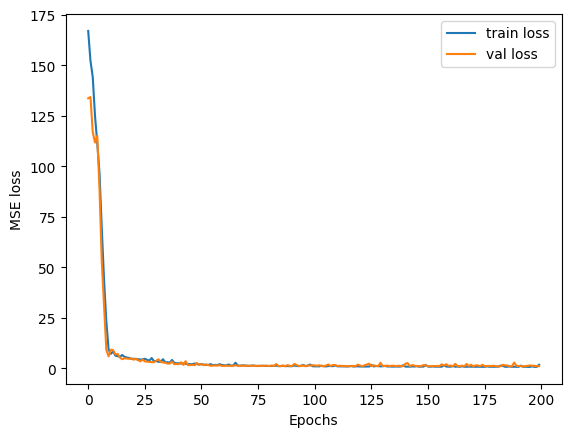

Tester: Regression model learning OK


In [63]:
# implement your solution BELOW
loss_fun = nn.MSELoss()

show_log = True   #ki lehet kapcsolni a logolast, hogy ne arassza el a terminalt
# hiperparameterek
epoch_count = 200
learning_rate = 0.001
optim = torch.optim.Adam(reg_model.parameters(), lr=learning_rate)
patience = 40   # ennyi epochot varunk javulasra, ha nem tortenik meg, akkor early stopping

train_losses = []   # gyujtok letrehozasa az epochokon beluli mean koltsegek tarolasahoz
val_losses = []
best_reg_model = None # az elmentett legjobb parameteru modellhez
best_val_loss = float('inf')  # poz. vegtelen beallitasa

early_idx = 0 # index az early stoppinghoz, az eddigi legjobb parameterekhez tartozo indexet tarolja, ehhez kepest merem patiencet

for epoch_idx in range(epoch_count):    # minden egyes epochra:

    reg_model.train()     # train modba allitom a modellt
    epoch_losses_train = []    # ebbe gyujtom a lossokat a kesobbi mean-hez

    for train_data, train_labels in dataloader_reg_train: # vegigmegyek batchenkent az adaton
        optim.zero_grad()   # akkumulalodott gradiensek nullazasa
        train_pred = reg_model(train_data)   # az adott batchet atkuldom a modellen, es az outputokat eltarolom
        loss = loss_fun(train_pred, train_labels)    # koltseg megallapitasa MSE-vel
        epoch_losses_train.append(loss.detach())    # a gyujtobe teszem a koltseget
        loss.backward()   # paramok allitasa
        optim.step()

    avg_train_epoch_loss = torch.tensor(epoch_losses_train).mean()   # tensorra alakitom a tombot, majd mean-t szamolok ra
    train_losses.append(avg_train_epoch_loss)        # kiszamolt mean-t a kulso gyujtobe teszem

    reg_model.eval()     # kiertekelo modba allitom a modellt
    epoch_losses_val = []        # ebbe gyujtok a kesobbi mean-hez

    for val_data, val_labels in dataloader_reg_val: # vegigmegyek batchenkent az adaton
        with torch.no_grad():     # gradiens-szamolas kikapcsolasa a hatekonysagert
            val_pred = reg_model(val_data)        # az adott batchet atkuldom a modellen, es az outputokat eltarolom
        loss = loss_fun(val_pred, val_labels)   # koltseg megallapitasa MSE-vel
        epoch_losses_val.append(loss)             # a gyujtobe teszem a koltseget

    avg_val_epoch_loss = torch.tensor(epoch_losses_val).mean()  # tensorra alakitom a tombot, majd mean-t szamolok ra
    val_losses.append(avg_val_epoch_loss)   # kiszamolt mean-t a kulso gyujtobe teszem

    if show_log:
      print(f"Epoch #{epoch_idx}, tr loss: {avg_train_epoch_loss}, val loss: {avg_val_epoch_loss}")  #logolas

    if avg_val_epoch_loss < best_val_loss:    #megnezem, hogy van e potencialisan uj legjobb modellem, ha igen, akkor kimentem valtozoba az adatait
        best_val_loss = avg_val_epoch_loss
        best_reg_model = copy.deepcopy(reg_model)
        early_idx = epoch_idx
        if show_log:
          print("    Early stopping: Best model updated.")


    if early_idx + patience < epoch_idx:      # ha sokaig nem javult, akkor leallitom az epochokat
        print(f"Training is terminated by early stopping at epoch {epoch_idx + 1}, best model was created at epoch {early_idx}.")
        break

losses = []
for_visual = True  #indikator, hogykiprinteltem-e mar azt a par elemet, amivel szemleltetheto a neuronhalo becslesi kepessege
for test_data, test_labels in dataloader_reg_test:    #megnezem, hogy a betanult modell hogyan teljesit a teszthalmazon
        best_reg_model.eval()   #kiertekelo modba allitom a legjobb modellt
        with torch.no_grad():   #mivel itt sem kell modositanom a parametereken, ezert a gradiens szamolast kikapcsolom
          test_pred = best_reg_model(test_data)     #kiertekelem batchenkent a modellen az adatokat
          losses.append(loss_fun(test_pred, test_labels))
          if for_visual == 0:   #a par szemlelteto jellegu pelda kiprintelese, ha meg nem tettuk meg
            print("A few true labels and what the model predicted for them:")
            for i in range(5):
              print(f"{float(test_labels[i])}    ~   {float(test_pred[i])}")
            for_visual = False


test_mse = torch.tensor(losses).mean()    #vegso teljesitmeny kiertekelese a tensorra alakitott koltseggyujtemennyel

plt.plot(train_losses, label='train loss')    #grafikont hozok letre a tanulas szemleltetesere
plt.plot(val_losses, label='val loss')
plt.xlabel('Epochs')
plt.ylabel('MSE loss')
plt.legend()
plt.show()
# implement your solution ABOVE

tester.test('reg_model_learning', test_mse)

## **G**: Az adat-iterátorok létrehozása a klasszifikációs feladathoz

Hasonlóan a D) feladathoz, itt is három adat-iterátort kell létrehoznunk, azonban ezúttal egy kissé eltérő feladatot fogunk megtanulni megoldani, így a visszaadott tenzorok alakja / adattípusa is eltérő lesz. **Állítsd elő** a `dataloader_cl_train`, `dataloader_cl_val`, `dataloader_cl_test` nevű **iterátorokat**, melyek ugyancsak a C) részfeladatban elkészült tanító-, validációs- és teszthalmazokat tartalmazó tömböket járják be! A klasszifikációs feladatban input változókként az összes változót felhasználjuk az adatbázisban, kivéve a három harmadév végi jegyét a diákoknak (`G1`, `G2`, `G3` nevű, #30, #31 és #32 indexű oszlopok az eredeti adatbázis szövegfájlban). Címkeként három kategóriát definiálunk és az összes diákot besoroljuk ezekbe a kategóriákba:
- **"Gyengén teljesítő diákok"** kategória, #0 kategóriaindex: azon diákok kerülnek ide, akiknek legalább két jegyük kisebb, mint 11.
- **"Közepesen teljesítő diákok"** kategória, #1 kategóriaindex: azon diákok kerülnek ide, akik átlagos jegye kisebb, mint 14, de nem tartoznak a "Gyengén teljesítő diákok" közé.
- **"Jól teljesítő diákok"** kategória, #2 kategóriaindex: azon diákok kerülnek ide, akik nem tartoznak a másik két kategóriába.

A fentiek alapján az iterátorok által visszaadott tenzorok alakja `(batch_size, 33)` és `(batch_size,)` lesz. Utóbbi (a címkéket tartalmazó tenzor) a diákok kategóriaindexét fogja tartalmazni (azaz 0, 1, vagy 2 értékeket, `torch.int64` adattípusban), előbbi pedig az adatbázis összes felhasznált változójának értékét a megfelelő mintaelemekre `torch.float32` adattípusban. `batch_size` ezúttal is a mintaelemek számát adja meg, ez kézzel beállítandó.

A **tanító és validációs halmazt felsoroló iterátorok véletlen sorrendben járják be** a hozzájuk tartozó mintaelemeket! A teszt halmazt felsoroló iterátor ne változtasson a `dataset_split_test` tömb sorrendjén!

In [64]:
# implement your solution BELOW


class Iterator2(Dataset):      #osztalyt hozok letre a harom iterator objektumhoz a Dataset szarmaztatasaval
    def __init__(self, dataset):
        self.dataset_cl = dataset
        self.shuffle_data_cl = np.random.permutation(dataset)    #megkereverem az inputot (de a teszthalmazt nem, mert ott shuffle=False)

    def __len__(self):    #szarmaztatashoz kell
        return len(self.dataset_cl)

    def __getitem__(self, idx):   #egy-egy sornak a felbontasa
        row_cl = self.shuffle_data_cl[idx]
        inputs = np.concatenate((row_cl[:30], row_cl[33:]), axis=0)
        isweak = [(row_cl[30] < 11) , (row_cl[31] < 11) , (row_cl[32] < 11)]
        weak = sum(isweak) > 1    #ez az osszeadas megteheto, mert a numpy a true-false ertekekhez szamot tarsit
        mediocre = not weak and row_cl[30:33].mean() < 14
        good = not weak and not mediocre
        return torch.tensor(inputs, dtype=torch.float32), torch.tensor(np.select([weak, mediocre, good], [0,1,2]), dtype = torch.int64)


dataset_train_cl = Iterator2(dataset_split_train)   # az iterator objektumokat itt hozom letre
dataset_val_cl = Iterator2(dataset_split_val)
dataset_test_cl = Iterator2(dataset_split_test)



#egy-egy tensorba beleteszem az iteratorral immar batchekre szedett adatokat
dataloader_cl_train = DataLoader(dataset_train_cl, batch_size=BATCH_SIZE, shuffle=True)   #megadom, hogy shuffle-eljunk e es hogy hany sort kerunk az iteratortol
dataloader_cl_val = DataLoader(dataset_val_cl, batch_size=BATCH_SIZE, shuffle=True)
dataloader_cl_test = DataLoader(dataset_test_cl, batch_size=BATCH_SIZE, shuffle=False)

# implement your solution ABOVE

tester.test('cl_iter', dataloader_cl_train, dataloader_cl_val, dataloader_cl_test)

Tester: Dataset iterators for classification task OK


## **H**: A klasszifikációs neuronháló definiálása

**Definiáld a klasszifikációs feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely a regressziós neuronhálót implementáló osztályhoz hasonlóan, az általános `torch.nn.Module` osztály leszármazottja! Példányosítsd az új osztályt és add értékül a `cl_model` nevű változónak a példányt!

A klasszifikációs neuronháló **tartalmazzon 3 teljesen összekötött réteget! Az első kettő réteg tartalmazzon egyenként 30 és 20 neuront és alkalmazza a ReLU aktivációs függvényt a rétegek után!** Az utolsó réteget a háromkategóriás klasszifikációnak megfelelően kell kialakítani!

In [65]:
# implement your solution BELOW

class ClModel(nn.Module):

  def __init__(self, input_dim):  #konstruktor benne a retegekkel
    super().__init__()  #az nn.Module orokitese
    self.classif1 = nn.Linear(input_dim, 30)
    self.classif2 = nn.Linear(30, 20)
    self.classif3 = nn.Linear(20, 3)

  def forward(self, x): #kiertekeles aktivacios fugvenyekkel egyutt
        x = torch.relu(self.classif1(x))
        x = torch.relu(self.classif2(x))
        x = self.classif3(x)
        return x

cl_model = ClModel(input_dim=33)  #letrehozom a neuronhalomat

# implement your solution ABOVE

tester.test('cl_model_architecture', cl_model)

Tester: Classification model architecture OK


## **I**: A háló betanítása (multi-class) klasszifikációs feladatra

**Tanítsd be a** `cl_model` **neuronhálót** a tanítóhalmazon a `dataloader_cl_train` iterátor segítségével és alkalmazd a `dataloader_cl_val` iterátort a validációhoz!

Alkalmazd a multi-class klasszifikációkor szokásosan használt **cross-entropy költséget**! **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonon a jelmagyarázat meglétére és a görbék könnyű elkülöníthetőségére figyelj ezúttal is!

A tanítást ezúttal az **early stopping** technika állítsa le! Amennyiben adott számú epoch-on keresztül (`patience`) nem javul a validációs költség, érjen véget a betanítás és **állítsuk vissza a `cl_model` súlyait abból az epoch-ból, amikor a legjobb volt a validációs költség!** Mindez automatikusan történjen!

A betanítás végeztével **mérd le az átlagos költséget a teljes teszthalmazon** és add értékül a kapott számot a `test_ce` változónak!

**Számold ki az _accuracy_ (pontosság) metrikát is a teszthalmaz elemein** és add értékül a kapott számot a `test_acc` változónak!! Az _accuracy_ metrika a helyesen klasszifikált mintaelemek arányát adja meg. Például, ha 150 mintaelem kategóriájának becslésekor 75 esetben találtuk el a helyes kategóriát, az _accuracy_ értéke 0.5 lesz.

Ezt követően, **válassz néhány mintaelemet a teszthalmazból** (például a `dataloader_cl_test` iterátor segítségével) és **adj becslést a címkéjükre** (a kategória indexére) az input változók értékei alapján, majd **írasd ki az egyes mintaelemekre a becsült és az igazi címkéjüket** (a kategóriák indexét)! Így példákon is láthatjuk, hogy mennyire ad jó becsléseket a neuronhálónk.

Végezetül, **számold ki a háló teszthalmazon vett konfúziós mátrixát és rajzold ki azt**! A konfúziós mátrix egy k x k méretű mátrix k kategória esetén, ahol az `[i,j]` indexű elem megadja, hogy az adathalmazon a modellünk hány `i` kategóriába tartozó mintaelemet becsült a `j` kategóriába. A modellünk jó teljesítményét jelzi, ha minél több elem kerül a konfúziós mátrix főátlójába. A számoláshoz felhasználhatsz külső könyvtárat is, de NumPy-ban is megoldható. A kirajzoláshoz használható például a `matplotlib.pyplot` csomag `imshow` függvénye. Figyelj rá, hogy a grafikonon világosan látszon, hogy melyik tengely sorolja fel az igazi kategóriákat és melyik a becsült kategóriákat, látszanak a sorok és oszlopok végén a kategóriák indexei és a cellákban az odatartozó mintaelemek darabszáma!


Training finished. Best model weights are restored.
A few true labels and what the model predicted for them:
2.0    ~   2.0
1.0    ~   1.0
1.0    ~   1.0
2.0    ~   2.0
2.0    ~   2.0


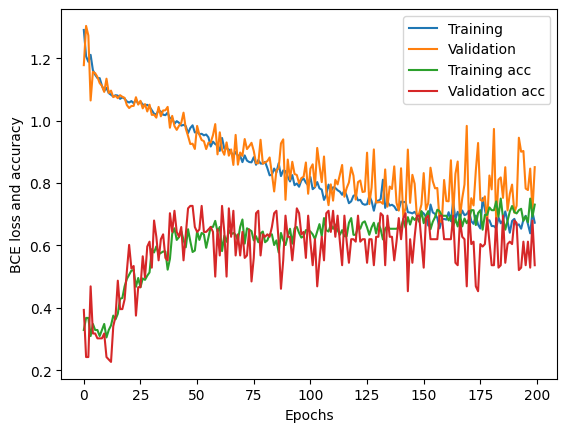

Tester: Classification model learning OK


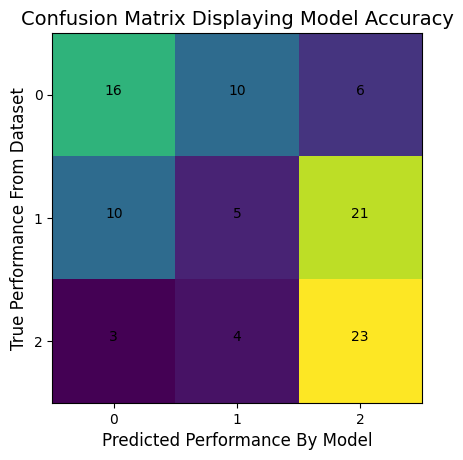

In [66]:
# implement your solution BELOW
import seaborn as sns
#hiperparameterek
epoch_count_cl = 200
patience_cl = 50
lr_cl= 0.0002

#fuggvenyek kivalasztasa

loss_fun_cl = nn.CrossEntropyLoss()
optim_cl = torch.optim.Adam(cl_model.parameters(), lr=lr_cl)
def acc_cl(pred, label):
  return np.count_nonzero(pred.argmax(dim=1) == label) / label.shape[0]


#gyujtoket elkeszitem a grafikonokhoz, es a legjobb modell megjegyzesehez
tr_losses_cl = []
tr_accs_cl = []
val_losses_cl = []
val_accs_cl = []
best_cl_model = None
best_val_loss_cl = float('inf')
early_ind_cl = 0


for epoch_ind in range(epoch_count_cl):   #minden egyes epochra:

    cl_model.train()  #train modba allitom a modellem
    tr_losses_cl_epoch = []   #belso gyujtok letrehozasa
    tr_accs_cl_epoch = []

    for tr_data, tr_labels in dataloader_cl_train:
        optim_cl.zero_grad()          #felgyulemlett gradiensek nullazasa
        tr_pred = cl_model(tr_data)     #modellen atkuldom az adatokat, elmentem az outputot (batch_size,3) alakban
        tr_loss = loss_fun_cl(tr_pred, tr_labels)   #koltseg kiszamitasa
        tr_acc = acc_cl(tr_pred,tr_labels)            #accuracy kiszamitasa

        #metrikakat hozzafuzom a belso gyujtohoz
        tr_losses_cl_epoch.append(tr_loss.detach())
        tr_accs_cl_epoch.append(tr_acc)

        #parameterek allistasa
        tr_loss.backward()
        optim_cl.step()


    #tensorra alakitom a belso gyujtoket, majd atlagolom, vegul a kulso gyujtohoz fuzom az atlagukat
    epoch_avg_tr_loss = torch.tensor(tr_losses_cl_epoch).mean()
    tr_losses_cl.append(epoch_avg_tr_loss)
    epoch_avg_tr_acc = torch.tensor(tr_accs_cl_epoch).mean()
    tr_accs_cl.append(epoch_avg_tr_acc)

    #kovetkezik a validacios halmaznak a kiertekelese:
    val_losses_cl_epoch = []
    val_accs_cl_epoch = []

    for val_data, val_labels in dataloader_cl_val:
        cl_model.eval()   #kiertekelo modba allitom a modellt
        with torch.no_grad():   #mivel itt nem szamolok gradienst, ezert kikapcsolom a hatekonyitashoz
            val_pred = cl_model(val_data)   #minden batch atkuldese a modellen, eredmeny elmentese
            val_loss = loss_fun_cl(val_pred, val_labels)   #koltseg kiszamitasa
            val_acc = acc_cl(val_pred, val_labels)   #accuracy kiszamitasa
            val_losses_cl_epoch.append(val_loss)      #nincsen szukseg itt mar a detach-re
            val_accs_cl_epoch.append(val_acc)

    #ismet tensorra alakitom a belso gyujtoket, majd atlagolom, vegul a kulso gyujtohoz fuzom az atlagukat
    epoch_avg_val_loss= torch.tensor(val_losses_cl_epoch).mean()
    val_losses_cl.append(epoch_avg_val_loss)
    epoch_avg_val_acc = torch.tensor(val_accs_cl_epoch).mean()
    val_accs_cl.append(epoch_avg_val_acc)

    #a vizsgalatot azzal zarom, hogy ellenorzom, sikerult-e jobb modellt talalni, ha igen, akkor elmentem, de ha nem, akkor megnezem, eleg regen volt-e mar a leallashoz
    if epoch_avg_val_loss < best_val_loss_cl:
        best_val_loss_cl = epoch_avg_val_loss
        best_cl_model = copy.deepcopy(cl_model)
        early_ind_cl = epoch_ind

    if early_ind_cl + patience_cl < epoch_ind:
        print("Training is terminated by early stopping.")
        break

#visszaterek a legjobb modellhez a train befejeztevel, hogy majd ezen teszteljek:
print("Training finished. Best model weights are restored.")
cl_model = best_cl_model

#gyujtoket elokeszitem
test_losses_cl = []
test_accs_cl = []
test_labelss = []
test_preds = []

for_visual = True
for test_data, test_labels in dataloader_cl_test:
    with torch.no_grad():   #gradienszamolast kikapcsolom, mert a teszteleshez nem kell
        test_pred = cl_model(test_data) #kiertekelek a legjobb modellel
        test_losses_cl.append(loss_fun_cl(test_pred, test_labels))
        test_accs_cl.append(acc_cl(test_pred, test_labels))
        test_labelss.append(test_labels)
        test_preds.append(test_pred)
        if for_visual:   #a par szemlelteto jellegu pelda kiprintelese, ha meg nem tettuk meg
            print("A few true labels and what the model predicted for them:")
            for i in range(5):
              print(f"{float(test_labels[i])}    ~   {float(torch.argmax(test_pred[i], dim=0))}")
            for_visual = False


test_labelss = torch.cat(test_labelss).numpy()    #tensorok keszitese
test_preds = torch.cat(test_preds).argmax(dim=1).numpy()
test_ce = torch.tensor(test_losses_cl).mean()
test_acc = torch.tensor(test_accs_cl).mean()

plt.plot(tr_losses_cl, label='Training')      #tanitasi folyamat diagramja
plt.plot(val_losses_cl, label='Validation')
plt.plot(tr_accs_cl, label='Training acc')
plt.plot(val_accs_cl, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss and accuracy')
plt.legend()
plt.show()

matrix_cl = confusion_matrix(test_labelss, test_preds) #konfuzios matrixomat letrehozom
plt.imshow(conf)  #kepkent jelenitem meg
plt.title('Confusion Matrix Displaying Model Accuracy', fontsize=14) #cim
#elokeszitem a tengelyeket:
plt.xlabel('Predicted Performance By Model', fontsize=12) #vizszintes tengely nevadasa
plt.ylabel('True Performance From Dataset', fontsize=12) #fuggoleges tengely nevadasa
plt.xticks(range(3))
plt.yticks(range(3))
for i in range(3):
  for j in range(3):
    value = conf[i, j]
    plt.text(j, i, value, horizontalalignment = "center") #ertek elhelyezese a megfelelo metszetre


# implement your solution ABOVE

tester.test('cl_model_learning', test_ce, test_acc)